#Predicción De Fallas en Máquinas Utilizando Datos De Sensores
##STEVEN DAVID LASCARRO LEON
###CODIGO: 2204003

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/IA_2026-2/ProyectoIA.csv')



In [4]:
# @title
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 944 entries, 0 to 943
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   footfall     944 non-null    int64
 1   tempMode     944 non-null    int64
 2   AQ           944 non-null    int64
 3   USS          944 non-null    int64
 4   CS           944 non-null    int64
 5   VOC          944 non-null    int64
 6   RP           944 non-null    int64
 7   IP           944 non-null    int64
 8   Temperature  944 non-null    int64
 9   fail         944 non-null    int64
dtypes: int64(10)
memory usage: 73.9 KB


In [5]:
df.head()

,footfall,tempMode,AQ,USS,CS,VOC,RP,IP,Temperature,fail
0,0,7,7,1,6,6,36,3,1,1
1,190,1,3,3,5,1,20,4,1,0
2,31,7,2,2,6,1,24,6,1,0
3,83,4,3,4,5,1,28,6,1,0
4,640,7,5,6,4,0,68,6,1,0


In [6]:
df.columns

Index(['footfall', 'tempMode', 'AQ', 'USS', 'CS', 'VOC', 'RP', 'IP',
       'Temperature', 'fail'],
      dtype='object')

In [7]:
df.describe()

,footfall,tempMode,AQ,USS,CS,VOC,RP,IP,Temperature,fail
count,944.000000,944.000000,944.000000,944.000000,944.000000,944.000000,944.000000,944.000000,944.000000,944.000000
mean,306.381356,3.727754,4.325212,2.939619,5.394068,2.842161,47.043432,4.565678,16.331568,0.416314
std,1082.606745,2.677235,1.438436,1.383725,1.269349,2.273337,16.423130,1.599287,5.974781,0.493208
min,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000,19.000000,1.000000,1.000000,0.000000
25%,1.000000,1.000000,3.000000,2.000000,5.000000,1.000000,34.000000,3.000000,14.000000,0.000000
50%,22.000000,3.000000,4.000000,3.000000,6.000000,2.000000,44.000000,4.000000,17.000000,0.000000
75%,110.000000,7.000000,6.000000,4.000000,6.000000,5.000000,58.000000,6.000000,21.000000,1.000000
max,7300.000000,7.000000,7.000000,7.000000,7.000000,6.000000,91.000000,7.000000,24.000000,1.000000


In [8]:
# 1. Calcular Q1 (25%) y Q3 (75%)
Q1 = df['tempMode'].quantile(0.25)
Q3 = df['tempMode'].quantile(0.75)

# 2. Calcular el IQR
IQR = Q3 - Q1

# 3. Definir límites inferior y superior
limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

# 4. Imprimir resultados
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Límite inferior:", limite_inferior)
print("Límite superior:", limite_superior)

Q1: 1.0
Q3: 7.0
IQR: 6.0
Límite inferior: -8.0
Límite superior: 16.0


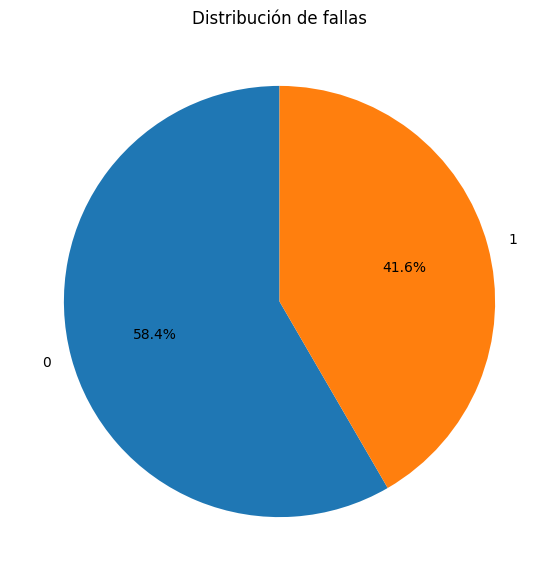

In [9]:
import matplotlib.pyplot as plt

conteo_fail = df['fail'].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    conteo_fail,
    labels=conteo_fail.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribución de fallas')
plt.show()

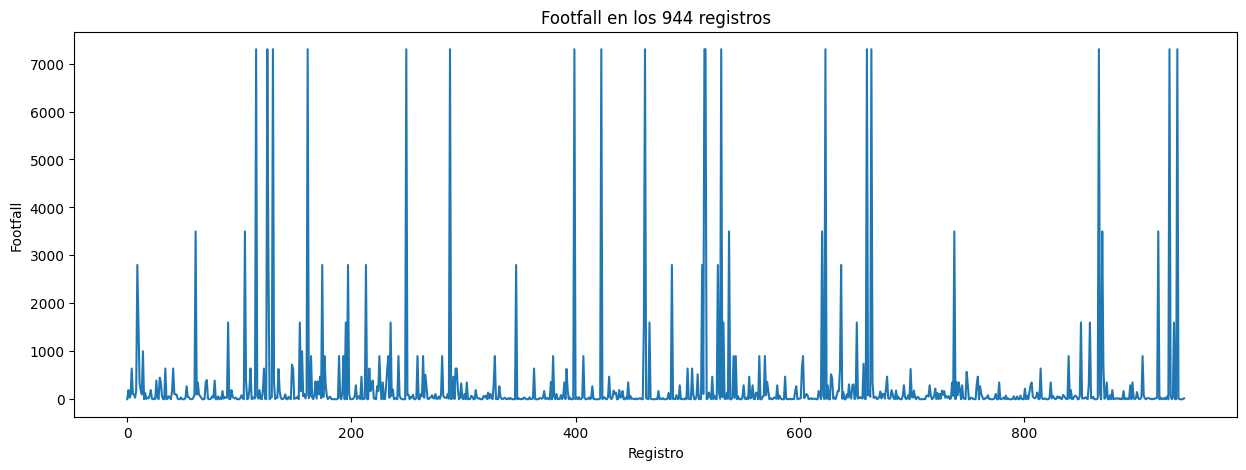

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.plot(df['footfall'])

plt.title('Footfall en los 944 registros')
plt.xlabel('Registro')
plt.ylabel('Footfall')

plt.show()

# 📊 Análisis del Dataset
## Machine Failure Prediction using Sensor Data

---

### Tipo de problema

**Clasificación binaria**

El objetivo principal del dataset es predecir si una máquina presenta
una falla o no, utilizando diferentes variables obtenidas mediante sensores.

###  Variable objetivo

| Variable | Descripción | Clases |
|----------|-------------|--------|
| `fail` | Indica si la máquina presenta una falla | `0 = No falla` / `1 = Falla` |

### 🔎 Variables de entrada

Las variables utilizadas para realizar la predicción son:

- `footfall`
- `tempMode`
- `AQ`
- `USS`
- `CS`
- `VOC`
- `RP`
- `IP`
- `Temperature`

### ¿Por qué es clasificación?

Es un problema de **clasificación binaria** porque la variable objetivo
`fail` solamente puede representar dos estados:

> **0 → La máquina no falla**  
> **1 → La máquina falla**


##Limpieza del dataset


In [11]:
# Revisar valores nulos
print("Valores nulos por columna:")
display(df.isnull().sum())

print("Total de valores nulos:", df.isnull().sum().sum())

# Revisar registros duplicados
print("\nCantidad de registros duplicados:", df.duplicated().sum())

# Revisar dimensiones y tipos de datos
print("\nDimensiones del dataset:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)

# Comprobar la variable objetivo
print("\nValores de la variable fail:")
print(df['fail'].value_counts(dropna=False))

Valores nulos por columna:


,0
footfall,0
tempMode,0
AQ,0
USS,0
CS,0
VOC,0
RP,0
IP,0
Temperature,0
fail,0


Total de valores nulos: 0

Cantidad de registros duplicados: 1

Dimensiones del dataset: (944, 10)

Tipos de datos:
footfall       int64
tempMode       int64
AQ             int64
USS            int64
CS             int64
VOC            int64
RP             int64
IP             int64
Temperature    int64
fail           int64
dtype: object

Valores de la variable fail:
fail
0    551
1    393
Name: count, dtype: int64


In [12]:
columnas_numericas = df.drop(columns=['fail']).select_dtypes(include='number').columns

resumen_atipicos = []

for columna in columnas_numericas:
    Q1 = df[columna].quantile(0.25)
    Q3 = df[columna].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    cantidad_atipicos = (
        (df[columna] < limite_inferior) |
        (df[columna] > limite_superior)
    ).sum()

    resumen_atipicos.append({
        'Variable': columna,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Límite inferior': limite_inferior,
        'Límite superior': limite_superior,
        'Cantidad de atípicos': int(cantidad_atipicos)
    })

display(pd.DataFrame(resumen_atipicos))

,Variable,Q1,Q3,IQR,Límite inferior,Límite superior,Cantidad de atípicos
0,footfall,1.0,110.0,109.0,-162.5,273.5,154
1,tempMode,1.0,7.0,6.0,-8.0,16.0,0
2,AQ,3.0,6.0,3.0,-1.5,10.5,0
3,USS,2.0,4.0,2.0,-1.0,7.0,0
4,CS,5.0,6.0,1.0,3.5,7.5,87
5,VOC,1.0,5.0,4.0,-5.0,11.0,0
6,RP,34.0,58.0,24.0,-2.0,94.0,0
7,IP,3.0,6.0,3.0,-1.5,10.5,0
8,Temperature,14.0,21.0,7.0,3.5,31.5,48


##Particionado (80/20)


In [13]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['fail'])
y = df['fail'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=21,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

print("\nDistribución de fail en entrenamiento:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nDistribución de fail en prueba:")
print(y_test.value_counts(normalize=True).sort_index())

Datos de entrenamiento: (755, 9)
Datos de prueba: (189, 9)

Distribución de fail en entrenamiento:
fail
0    0.584106
1    0.415894
Name: proportion, dtype: float64

Distribución de fail en prueba:
fail
0    0.582011
1    0.417989
Name: proportion, dtype: float64


##Configuración de validación cruzada

In [14]:
from sklearn.model_selection import KFold, cross_val_score, validation_curve
from sklearn.metrics import make_scorer
import numpy as np

cv = KFold(n_splits=10, shuffle=True, random_state=21)

# TPR: proporción de máquinas con falla (clase 1) correctamente detectadas.
def tpr(estimator, X_fold, y_fold):
    y_real = np.asarray(y_fold)
    y_pred = estimator.predict(X_fold)
    positivos = (y_real == 1)

    if positivos.sum() == 0:
        return 0.0

    return np.mean(y_pred[positivos] == y_real[positivos])

# TNR: proporción de máquinas sin falla (clase 0) correctamente identificadas.
def tnr(estimator, X_fold, y_fold):
    y_real = np.asarray(y_fold)
    y_pred = estimator.predict(X_fold)
    negativos = (y_real == 0)

    if negativos.sum() == 0:
        return 0.0

    return np.mean(y_pred[negativos] == y_real[negativos])

print("KFold configurado con 10 particiones.")

KFold configurado con 10 particiones.


##Modelo Decision Tree


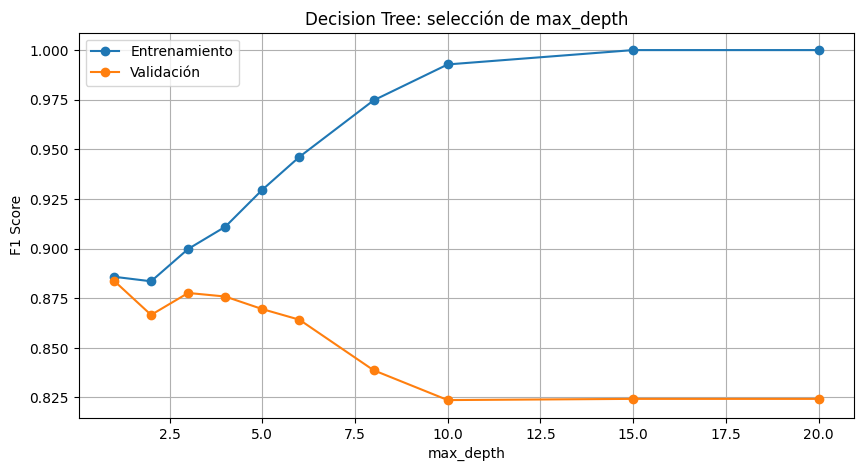

Mejor max_depth: 1
Mejor F1 de validación: 0.8838


In [15]:
from sklearn.tree import DecisionTreeClassifier

profundidades = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20]

modelo_dt_base = DecisionTreeClassifier(random_state=21)

train_scores_dt, val_scores_dt = validation_curve(
    modelo_dt_base,
    X_train,
    y_train,
    param_name='max_depth',
    param_range=profundidades,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

train_mean_dt = train_scores_dt.mean(axis=1)
val_mean_dt = val_scores_dt.mean(axis=1)

plt.figure(figsize=(10, 5))
plt.plot(profundidades, train_mean_dt, marker='o', label='Entrenamiento')
plt.plot(profundidades, val_mean_dt, marker='o', label='Validación')
plt.xlabel('max_depth')
plt.ylabel('F1 Score')
plt.title('Decision Tree: selección de max_depth')
plt.legend()
plt.grid()
plt.show()

mejor_depth = profundidades[int(np.argmax(val_mean_dt))]
print("Mejor max_depth:", mejor_depth)
print("Mejor F1 de validación:", round(float(np.max(val_mean_dt)), 4))

In [16]:
from sklearn.metrics import accuracy_score, f1_score
modelo_dt = DecisionTreeClassifier(
    max_depth=mejor_depth,
    random_state=21
)

modelo_dt.fit(X_train, y_train)
pred_dt = modelo_dt.predict(X_test)

print("Decision Tree - conjunto de prueba")
print("Accuracy:", accuracy_score(y_test, pred_dt))
print("F1 Score:", f1_score(y_test, pred_dt, zero_division=0))

Decision Tree - conjunto de prueba
Accuracy: 0.9153439153439153
F1 Score: 0.9024390243902439


##Modelo Random Forest


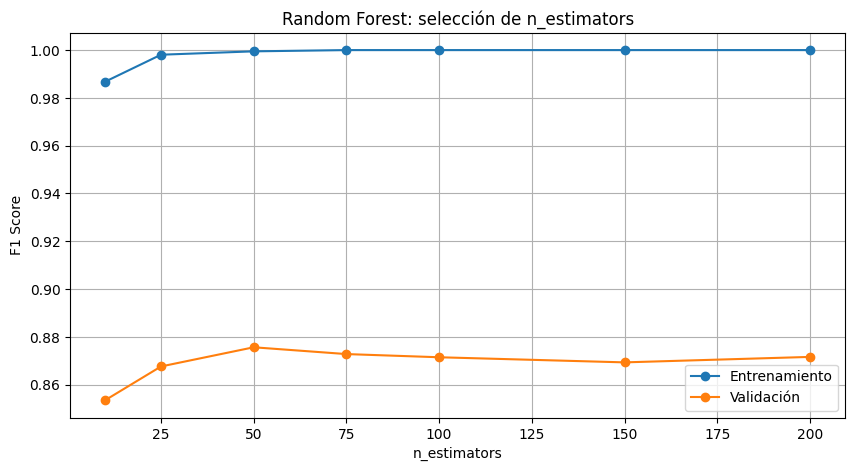

Mejor n_estimators: 50
Mejor F1 de validación: 0.8756


In [17]:
from sklearn.ensemble import RandomForestClassifier

estimadores = [10, 25, 50, 75, 100, 150, 200]

modelo_rf_base = RandomForestClassifier(
    random_state=21,
    n_jobs=-1
)

train_scores_rf, val_scores_rf = validation_curve(
    modelo_rf_base,
    X_train,
    y_train,
    param_name='n_estimators',
    param_range=estimadores,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

train_mean_rf = train_scores_rf.mean(axis=1)
val_mean_rf = val_scores_rf.mean(axis=1)

plt.figure(figsize=(10, 5))
plt.plot(estimadores, train_mean_rf, marker='o', label='Entrenamiento')
plt.plot(estimadores, val_mean_rf, marker='o', label='Validación')
plt.xlabel('n_estimators')
plt.ylabel('F1 Score')
plt.title('Random Forest: selección de n_estimators')
plt.legend()
plt.grid()
plt.show()

mejor_estimadores = estimadores[int(np.argmax(val_mean_rf))]
print("Mejor n_estimators:", mejor_estimadores)
print("Mejor F1 de validación:", round(float(np.max(val_mean_rf)), 4))

In [18]:
modelo_rf = RandomForestClassifier(
    n_estimators=mejor_estimadores,
    random_state=21,
    n_jobs=-1
)

modelo_rf.fit(X_train, y_train)
pred_rf = modelo_rf.predict(X_test)

print("Random Forest - conjunto de prueba")
print("Accuracy:", accuracy_score(y_test, pred_rf))
print("F1 Score:", f1_score(y_test, pred_rf, zero_division=0))

Random Forest - conjunto de prueba
Accuracy: 0.9153439153439153
F1 Score: 0.9


###Importancia de las variables

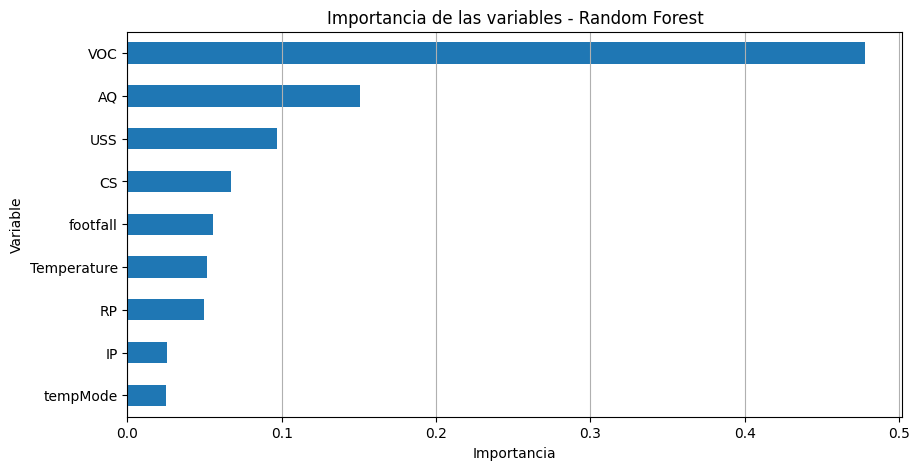

,Importancia
VOC,0.478208
AQ,0.150806
USS,0.097159
CS,0.066856
footfall,0.055149
Temperature,0.051638
RP,0.049427
IP,0.025658
tempMode,0.025099


In [19]:
importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
importancias.sort_values().plot(kind='barh')
plt.title('Importancia de las variables - Random Forest')
plt.xlabel('Importancia')
plt.ylabel('Variable')
plt.grid(axis='x')
plt.show()

display(importancias.to_frame(name='Importancia'))

##Modelo Support Vector Machine (SVM)


In [20]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

kernels = ['linear', 'poly', 'rbf']
resultados_svm = {}

for kernel in kernels:
    modelo_kernel = Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(kernel=kernel))
    ])

    scores = cross_val_score(
        modelo_kernel,
        X_train,
        y_train,
        cv=cv,
        scoring='f1',
        n_jobs=-1
    )

    resultados_svm[kernel] = scores

    print(
        f"Kernel {kernel}: F1 = {scores.mean():.4f} "
        f"(+/- {scores.std():.4f})"
    )

Kernel linear: F1 = 0.8840 (+/- 0.0383)
Kernel poly: F1 = 0.8644 (+/- 0.0454)
Kernel rbf: F1 = 0.8700 (+/- 0.0628)


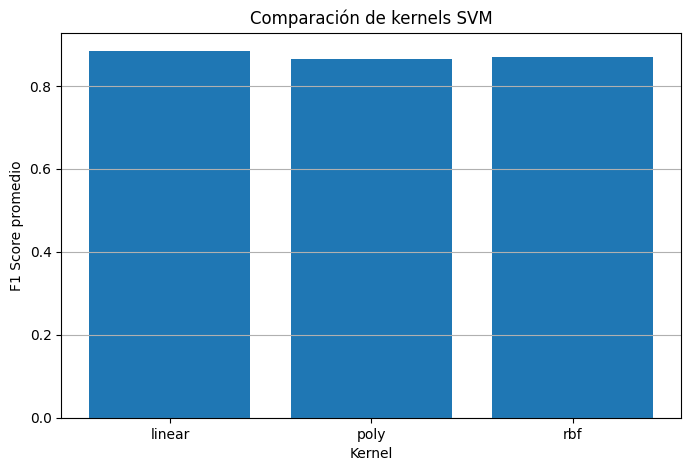

Mejor kernel: linear


In [21]:
promedios_svm = {
    kernel: scores.mean()
    for kernel, scores in resultados_svm.items()
}

plt.figure(figsize=(8, 5))
plt.bar(promedios_svm.keys(), promedios_svm.values())
plt.title('Comparación de kernels SVM')
plt.xlabel('Kernel')
plt.ylabel('F1 Score promedio')
plt.grid(axis='y')
plt.show()

mejor_kernel = max(promedios_svm, key=promedios_svm.get)
print("Mejor kernel:", mejor_kernel)

In [22]:
modelo_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel=mejor_kernel))
])

modelo_svm.fit(X_train, y_train)
pred_svm = modelo_svm.predict(X_test)

print("SVM - conjunto de prueba")
print("Accuracy:", accuracy_score(y_test, pred_svm))
print("F1 Score:", f1_score(y_test, pred_svm, zero_division=0))

SVM - conjunto de prueba
Accuracy: 0.9259259259259259
F1 Score: 0.9146341463414634


##Implementacion de Cross Validation


In [23]:
modelos_tradicionales = {
    'Decision Tree': modelo_dt,
    'Random Forest': modelo_rf,
    'SVM': modelo_svm
}

resultados_cv = []

for nombre, estimador in modelos_tradicionales.items():
    print("\nModelo:", nombre)

    scores_accuracy = cross_val_score(
        estimador, X_train, y_train,
        cv=cv, scoring='accuracy', n_jobs=-1
    )

    scores_tpr = cross_val_score(
        estimador, X_train, y_train,
        cv=cv, scoring=tpr, n_jobs=-1
    )

    scores_tnr = cross_val_score(
        estimador, X_train, y_train,
        cv=cv, scoring=tnr, n_jobs=-1
    )

    resultados_cv.append({
        'Modelo': nombre,
        'Accuracy promedio': scores_accuracy.mean(),
        'Accuracy desviación': scores_accuracy.std(),
        'TPR promedio': scores_tpr.mean(),
        'TPR desviación': scores_tpr.std(),
        'TNR promedio': scores_tnr.mean(),
        'TNR desviación': scores_tnr.std()
    })

    print("Accuracy %.3f (+/- %.5f)" % (scores_accuracy.mean(), scores_accuracy.std()))
    print("TPR      %.3f (+/- %.5f)" % (scores_tpr.mean(), scores_tpr.std()))
    print("TNR      %.3f (+/- %.5f)" % (scores_tnr.mean(), scores_tnr.std()))

df_cv = pd.DataFrame(resultados_cv)
display(df_cv.round(4))


Modelo: Decision Tree
Accuracy 0.902 (+/- 0.02776)
TPR      0.913 (+/- 0.04176)
TNR      0.894 (+/- 0.04535)

Modelo: Random Forest
Accuracy 0.899 (+/- 0.02929)
TPR      0.877 (+/- 0.05640)
TNR      0.916 (+/- 0.03676)

Modelo: SVM
Accuracy 0.905 (+/- 0.02680)
TPR      0.896 (+/- 0.06058)
TNR      0.910 (+/- 0.03340)


,Modelo,Accuracy promedio,Accuracy desviación,TPR promedio,TPR desviación,TNR promedio,TNR desviación
0,Decision Tree,0.9020,0.0278,0.9128,0.0418,0.8941,0.0454
1,Random Forest,0.8995,0.0293,0.8772,0.0564,0.9155,0.0368
2,SVM,0.9047,0.0268,0.8965,0.0606,0.9096,0.0334


##Deep Learning


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

In [25]:
import random
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

SEED = 21
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Separar validación a partir del conjunto de entrenamiento.
X_train_dl, X_val_dl, y_train_dl, y_val_dl = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=21,
    stratify=y_train
)

# El escalador se ajusta solo con el subconjunto de entrenamiento de DL.
scaler_dl = StandardScaler()
X_train_scaled = scaler_dl.fit_transform(X_train_dl)
X_val_scaled = scaler_dl.transform(X_val_dl)

print("Entrenamiento DL:", X_train_scaled.shape)
print("Validación DL:", X_val_scaled.shape)

Entrenamiento DL: (604, 9)
Validación DL: (151, 9)


In [26]:
arquitecturas = {
    'Red 3 capas': [64, 128, 128],
    'Red 6 capas': [64, 64, 128, 128, 256, 256],
    'Red 10 capas': [128, 128, 128, 128, 128,
                     128, 128, 128, 128, 128]
}

def crear_modelo(neuronas, n_variables):
    modelo = Sequential()
    modelo.add(Input(shape=(n_variables,)))

    for cantidad in neuronas:
        modelo.add(Dense(cantidad, activation='relu'))

    modelo.add(Dense(1, activation='sigmoid'))

    modelo.compile(
        optimizer=Adam(),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return modelo

print("Arquitecturas definidas:")
for nombre, capas in arquitecturas.items():
    print(nombre, ":", capas)

Arquitecturas definidas:
Red 3 capas : [64, 128, 128]
Red 6 capas : [64, 64, 128, 128, 256, 256]
Red 10 capas : [128, 128, 128, 128, 128, 128, 128, 128, 128, 128]


In [27]:
epocas = [5, 10, 50, 100]
resultados_dl = []

for nombre, neuronas in arquitecturas.items():
    for cantidad_epocas in epocas:
        print(f"Entrenando {nombre} con {cantidad_epocas} épocas...")

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)

        modelo = crear_modelo(
            neuronas,
            n_variables=X_train_scaled.shape[1]
        )

        modelo.fit(
            X_train_scaled,
            y_train_dl,
            epochs=cantidad_epocas,
            batch_size=32,
            validation_data=(X_val_scaled, y_val_dl),
            verbose=0
        )

        probabilidades = modelo.predict(X_val_scaled, verbose=0).ravel()
        predicciones = (probabilidades >= 0.5).astype(int)

        resultados_dl.append({
            'Arquitectura': nombre,
            'Neuronas': str(neuronas),
            'Epochs': cantidad_epocas,
            'Accuracy': accuracy_score(y_val_dl, predicciones),
            'Precision': precision_score(y_val_dl, predicciones, zero_division=0),
            'Recall': recall_score(y_val_dl, predicciones, zero_division=0),
            'F1 Score': f1_score(y_val_dl, predicciones, zero_division=0)
        })

df_dl = pd.DataFrame(resultados_dl)
display(df_dl.sort_values('F1 Score', ascending=False).round(4))

Entrenando Red 3 capas con 5 épocas...
Entrenando Red 3 capas con 10 épocas...
Entrenando Red 3 capas con 50 épocas...


Entrenando Red 3 capas con 100 épocas...
Entrenando Red 6 capas con 5 épocas...
Entrenando Red 6 capas con 10 épocas...
Entrenando Red 6 capas con 50 épocas...
Entrenando Red 6 capas con 100 épocas...
Entrenando Red 10 capas con 5 épocas...
Entrenando Red 10 capas con 10 épocas...
Entrenando Red 10 capas con 50 épocas...
Entrenando Red 10 capas con 100 épocas...


,Arquitectura,Neuronas,Epochs,Accuracy,Precision,Recall,F1 Score
1,Red 3 capas,"[64, 128, 128]",10,0.9338,0.8955,0.9524,0.9231
9,Red 10 capas,"[128, 128, 128, 128, 128, 128, 128, 128, 128, ...",10,0.9272,0.8714,0.9683,0.9173
4,Red 6 capas,"[64, 64, 128, 128, 256, 256]",5,0.9272,0.8824,0.9524,0.9160
8,Red 10 capas,"[128, 128, 128, 128, 128, 128, 128, 128, 128, ...",5,0.9205,0.8696,0.9524,0.9091
0,Red 3 capas,"[64, 128, 128]",5,0.9205,0.8806,0.9365,0.9077
5,Red 6 capas,"[64, 64, 128, 128, 256, 256]",10,0.9073,0.8451,0.9524,0.8955
7,Red 6 capas,"[64, 64, 128, 128, 256, 256]",100,0.9073,0.8657,0.9206,0.8923
6,Red 6 capas,"[64, 64, 128, 128, 256, 256]",50,0.9073,0.8657,0.9206,0.8923
11,Red 10 capas,"[128, 128, 128, 128, 128, 128, 128, 128, 128, ...",100,0.9073,0.8657,0.9206,0.8923
10,Red 10 capas,"[128, 128, 128, 128, 128, 128, 128, 128, 128, ...",50,0.9007,0.8636,0.9048,0.8837


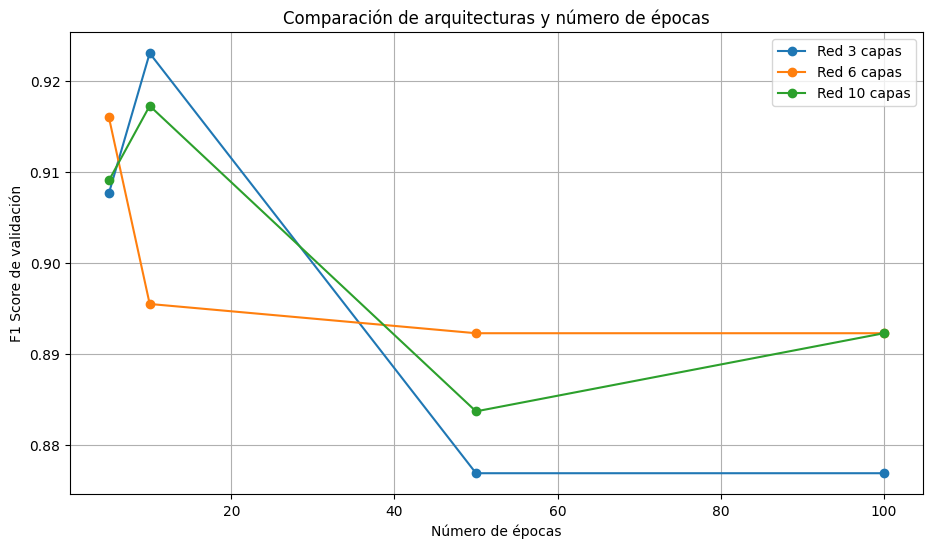

In [28]:
plt.figure(figsize=(11, 6))

for arquitectura in df_dl['Arquitectura'].unique():
    datos = df_dl[df_dl['Arquitectura'] == arquitectura]

    plt.plot(
        datos['Epochs'],
        datos['F1 Score'],
        marker='o',
        label=arquitectura
    )

plt.xlabel('Número de épocas')
plt.ylabel('F1 Score de validación')
plt.title('Comparación de arquitecturas y número de épocas')
plt.legend()
plt.grid()
plt.show()

###Selección de Epochs

In [29]:
mejor_configuracion = df_dl.loc[df_dl['F1 Score'].idxmax()]

print("Mejor configuración encontrada:")
display(mejor_configuracion.to_frame())

mejor_arquitectura = mejor_configuracion['Arquitectura']
mejores_epocas = int(mejor_configuracion['Epochs'])
neuronas_finales = arquitecturas[mejor_arquitectura]

# Ajustar el escalador con todo X_train y transformar X_test.
scaler_final = StandardScaler()
X_train_final = scaler_final.fit_transform(X_train)
X_test_final = scaler_final.transform(X_test)

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

modelo_dl = crear_modelo(
    neuronas_finales,
    n_variables=X_train_final.shape[1]
)

modelo_dl.fit(
    X_train_final,
    y_train,
    epochs=mejores_epocas,
    batch_size=32,
    verbose=0
)

probabilidades_dl = modelo_dl.predict(X_test_final, verbose=0).ravel()
pred_dl = (probabilidades_dl >= 0.5).astype(int)

print("Deep Learning - conjunto de prueba")
print("Accuracy:", accuracy_score(y_test, pred_dl))
print("F1 Score:", f1_score(y_test, pred_dl, zero_division=0))

Mejor configuración encontrada:


,1
Arquitectura,Red 3 capas
Neuronas,"[64, 128, 128]"
Epochs,10
Accuracy,0.933775
Precision,0.895522
Recall,0.952381
F1 Score,0.923077


Deep Learning - conjunto de prueba
Accuracy: 0.9206349206349206
F1 Score: 0.9079754601226994


## Desempeño final y barplot

In [30]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

predicciones_modelos = {
    'Decision Tree': pred_dt,
    'Random Forest': pred_rf,
    'SVM': pred_svm,
    'Deep Learning': pred_dl
}

resultados_finales = []

for nombre, predicciones in predicciones_modelos.items():
    resultados_finales.append({
        'Modelo': nombre,
        'Accuracy': accuracy_score(y_test, predicciones),
        'Precision': precision_score(y_test, predicciones, zero_division=0),
        'Recall / TPR': recall_score(y_test, predicciones, pos_label=1, zero_division=0),
        'TNR': recall_score(y_test, predicciones, pos_label=0, zero_division=0),
        'F1 Score': f1_score(y_test, predicciones, zero_division=0)
    })

df_resultados = pd.DataFrame(resultados_finales)
display(df_resultados.round(4))

,Modelo,Accuracy,Precision,Recall / TPR,TNR,F1 Score
0,Decision Tree,0.9153,0.8706,0.9367,0.9000,0.9024
1,Random Forest,0.9153,0.8889,0.9114,0.9182,0.9000
2,SVM,0.9259,0.8824,0.9494,0.9091,0.9146
3,Deep Learning,0.9206,0.8810,0.9367,0.9091,0.9080


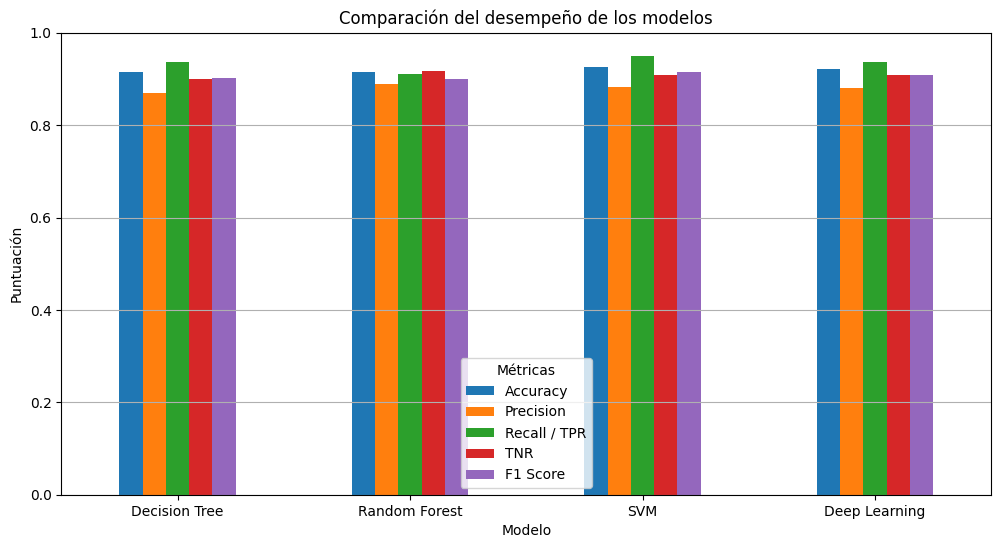

In [31]:
df_grafico = df_resultados.set_index('Modelo')

df_grafico.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Comparación del desempeño de los modelos')
plt.xlabel('Modelo')
plt.ylabel('Puntuación')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title='Métricas')
plt.grid(axis='y')
plt.show()

## 11. Matrices de confusión y reportes de clasificación

Las matrices permiten identificar verdaderos positivos, verdaderos negativos, falsos positivos y falsos negativos. En mantenimiento predictivo es especialmente importante observar los falsos negativos: máquinas que presentan una falla, pero el modelo predice que no fallarán.


 Decision Tree
              precision    recall  f1-score   support

No falla (0)       0.95      0.90      0.93       110
   Falla (1)       0.87      0.94      0.90        79

    accuracy                           0.92       189
   macro avg       0.91      0.92      0.91       189
weighted avg       0.92      0.92      0.92       189



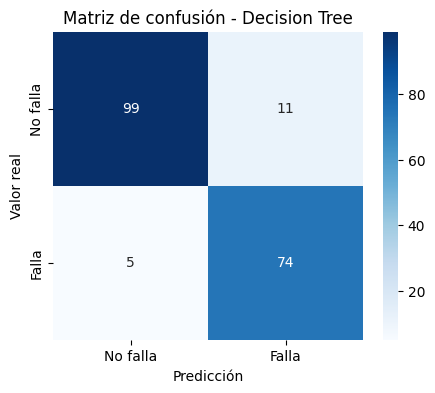


 Random Forest
              precision    recall  f1-score   support

No falla (0)       0.94      0.92      0.93       110
   Falla (1)       0.89      0.91      0.90        79

    accuracy                           0.92       189
   macro avg       0.91      0.91      0.91       189
weighted avg       0.92      0.92      0.92       189



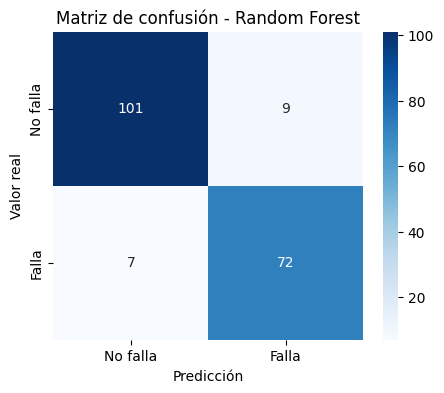


 SVM
              precision    recall  f1-score   support

No falla (0)       0.96      0.91      0.93       110
   Falla (1)       0.88      0.95      0.91        79

    accuracy                           0.93       189
   macro avg       0.92      0.93      0.92       189
weighted avg       0.93      0.93      0.93       189



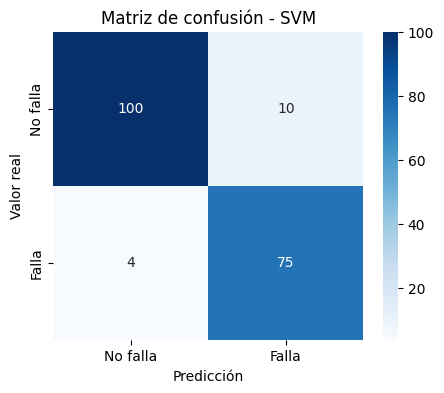


 Deep Learning
              precision    recall  f1-score   support

No falla (0)       0.95      0.91      0.93       110
   Falla (1)       0.88      0.94      0.91        79

    accuracy                           0.92       189
   macro avg       0.92      0.92      0.92       189
weighted avg       0.92      0.92      0.92       189



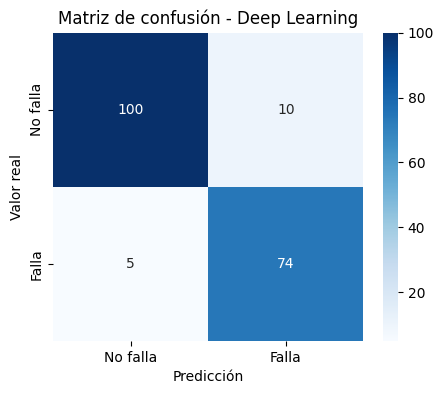

In [32]:
import seaborn as sns
import matplotlib.pyplot as plt

for nombre, predicciones in predicciones_modelos.items():
    print("\n", nombre)

    print(classification_report(
        y_test,
        predicciones,
        target_names=['No falla (0)', 'Falla (1)'],
        zero_division=0
    ))

    matriz = confusion_matrix(y_test, predicciones)

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        matriz,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No falla', 'Falla'],
        yticklabels=['No falla', 'Falla']
    )

    plt.title(f'Matriz de confusión - {nombre}')
    plt.xlabel('Predicción')
    plt.ylabel('Valor real')
    plt.show()

## I. Escalamiento de los datos

**Método elegido: StandardScaler.**

La variable `fail` se conserva aparte: no se utiliza como entrada del escalador ni de los algoritmos de agrupamiento.

In [33]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Separar las variables predictoras y conservar la clase real solo para comparar gráficamente.
X_clustering = df.drop(columns=['fail']).select_dtypes(include='number').copy()
y_real = df['fail'].astype(int).copy()

# Escalar las variables de los sensores.
scaler_clustering = StandardScaler()
X_scaled_clustering = scaler_clustering.fit_transform(X_clustering)

print("Dimensiones antes del escalamiento:", X_clustering.shape)
print("Dimensiones después del escalamiento:", X_scaled_clustering.shape)
print("Media aproximada de las variables escaladas:", X_scaled_clustering.mean(axis=0).round(3))
print("Desviación estándar aproximada:", X_scaled_clustering.std(axis=0).round(3))

Dimensiones antes del escalamiento: (944, 9)
Dimensiones después del escalamiento: (944, 9)
Media aproximada de las variables escaladas: [-0.  0.  0. -0. -0. -0. -0.  0.  0.]
Desviación estándar aproximada: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## II. Reducción de dimensionalidad con PCA


In [34]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_clustering)

df_pca = pd.DataFrame(
    X_pca,
    columns=['Componente principal 1', 'Componente principal 2']
)
df_pca['fail_real'] = y_real.to_numpy()

varianza_explicada = pca.explained_variance_ratio_

print("Varianza explicada por PC1:", round(varianza_explicada[0] * 100, 2), "%")
print("Varianza explicada por PC2:", round(varianza_explicada[1] * 100, 2), "%")
print("Varianza acumulada de los dos componentes:",
      round(varianza_explicada.sum() * 100, 2), "%")

Varianza explicada por PC1: 22.69 %
Varianza explicada por PC2: 17.97 %
Varianza acumulada de los dos componentes: 40.66 %


## III. Aplicación de K-Means


In [35]:
from sklearn.cluster import KMeans

n_clusters = y_real.nunique()

modelo_kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=21,
    n_init=10
)

clusters_kmeans = modelo_kmeans.fit_predict(X_pca)
df_pca['cluster_kmeans'] = clusters_kmeans

print("Número de clusters solicitado:", n_clusters)
print("\nCantidad de registros por cluster:")
print(pd.Series(clusters_kmeans).value_counts().sort_index())

Número de clusters solicitado: 2

Cantidad de registros por cluster:
0    403
1    541
Name: count, dtype: int64


## IV. Aplicación de DBSCAN y búsqueda de eps y min_samples


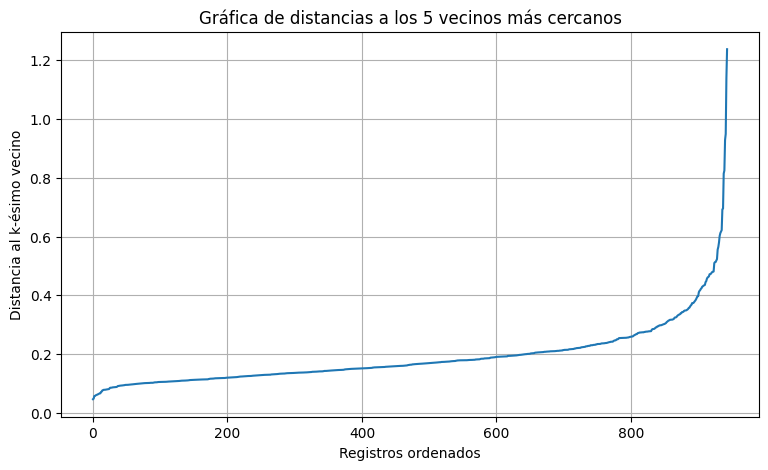

In [36]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

# Gráfica de distancias al k-ésimo vecino para orientar la búsqueda de eps.
min_samples_referencia = 5
vecinos = NearestNeighbors(n_neighbors=min_samples_referencia)
vecinos.fit(X_pca)
distancias, indices = vecinos.kneighbors(X_pca)

k_distancias = np.sort(distancias[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(k_distancias)
plt.title(f"Gráfica de distancias a los {min_samples_referencia} vecinos más cercanos")
plt.xlabel("Registros ordenados")
plt.ylabel("Distancia al k-ésimo vecino")
plt.grid()
plt.show()

In [37]:
# Búsqueda de combinaciones de eps y min_samples.
min_samples_opciones = [5, 10, 15, 20]
percentiles_eps = [70, 75, 80, 85, 90, 95, 98]

resultados_dbscan = []

for min_samples in min_samples_opciones:
    vecinos = NearestNeighbors(n_neighbors=min_samples)
    vecinos.fit(X_pca)
    distancias, _ = vecinos.kneighbors(X_pca)
    distancias_ordenadas = np.sort(distancias[:, -1])

    eps_opciones = np.unique(
        np.round(np.percentile(distancias_ordenadas, percentiles_eps), 3)
    )

    for eps in eps_opciones:
        etiquetas = DBSCAN(
            eps=float(eps),
            min_samples=min_samples
        ).fit_predict(X_pca)

        mascara_no_ruido = etiquetas != -1
        etiquetas_no_ruido = etiquetas[mascara_no_ruido]
        cantidad_clusters = len(set(etiquetas_no_ruido))
        porcentaje_ruido = (etiquetas == -1).mean() * 100

        # Silhouette solo es válido si quedan al menos dos clusters
        # y no todos los puntos pertenecen a un cluster diferente.
        if (cantidad_clusters >= 2 and
            cantidad_clusters < mascara_no_ruido.sum()):
            silhouette = silhouette_score(
                X_pca[mascara_no_ruido],
                etiquetas_no_ruido
            )
        else:
            silhouette = np.nan

        resultados_dbscan.append({
            'eps': float(eps),
            'min_samples': min_samples,
            'clusters': cantidad_clusters,
            'ruido_%': porcentaje_ruido,
            'silhouette': silhouette
        })

df_busqueda_dbscan = pd.DataFrame(resultados_dbscan)
display(df_busqueda_dbscan.sort_values(
    'silhouette',
    ascending=False,
    na_position='last'
).round(4))

,eps,min_samples,clusters,ruido_%,silhouette
14,0.377,15,2,15.4661,0.3772
21,0.441,20,2,14.5127,0.3761
15,0.403,15,2,11.9703,0.3734
22,0.471,20,2,8.5805,0.3616
16,0.439,15,2,8.5805,0.3577
9,0.357,10,3,8.7924,0.2401
3,0.260,5,4,9.3220,0.1540
8,0.321,10,4,12.6059,0.1283
7,0.302,10,6,15.8898,0.0070
2,0.235,5,9,11.0169,-0.1213


In [38]:
# Seleccionar la combinación válida con mayor Silhouette.
# Se evita elegir configuraciones que marquen más de la mitad de los datos como ruido.
candidatos_dbscan = df_busqueda_dbscan[
    df_busqueda_dbscan['silhouette'].notna() &
    (df_busqueda_dbscan['ruido_%'] <= 50)
].copy()

if not candidatos_dbscan.empty:
    mejor_dbscan = candidatos_dbscan.sort_values(
        'silhouette',
        ascending=False
    ).iloc[0]

    mejor_eps = float(mejor_dbscan['eps'])
    mejor_min_samples = int(mejor_dbscan['min_samples'])
    print("Se seleccionó la combinación con mayor Silhouette entre las opciones")
    print("que formaron al menos dos clusters y dejaron como máximo 50 % de ruido.")
else:
    # Si ninguna combinación cumple el criterio, usar la mejor Silhouette disponible
    # y advertir que debe revisarse la búsqueda.
    candidatos_validos = df_busqueda_dbscan[
        df_busqueda_dbscan['silhouette'].notna()
    ].copy()

    if candidatos_validos.empty:
        raise ValueError(
            "La búsqueda no encontró una combinación que formara al menos "
            "dos clusters. Se debe ampliar o ajustar el rango de eps."
        )

    mejor_dbscan = candidatos_validos.sort_values(
        'silhouette',
        ascending=False
    ).iloc[0]

    mejor_eps = float(mejor_dbscan['eps'])
    mejor_min_samples = int(mejor_dbscan['min_samples'])
    print("ADVERTENCIA: ninguna combinación cumplió el límite de ruido del 50 %.")
    print("Se muestra la mejor Silhouette disponible; revise la tabla y la gráfica.")

print("Mejor eps:", mejor_eps)
print("Mejor min_samples:", mejor_min_samples)
print("Clusters encontrados en la búsqueda:", int(mejor_dbscan['clusters']))
print("Porcentaje de ruido:", round(float(mejor_dbscan['ruido_%']), 2), "%")
print("Silhouette:", round(float(mejor_dbscan['silhouette']), 4))

Se seleccionó la combinación con mayor Silhouette entre las opciones
que formaron al menos dos clusters y dejaron como máximo 50 % de ruido.
Mejor eps: 0.377
Mejor min_samples: 15
Clusters encontrados en la búsqueda: 2
Porcentaje de ruido: 15.47 %
Silhouette: 0.3772


In [39]:
# Entrenar DBSCAN con los parámetros seleccionados.
modelo_dbscan = DBSCAN(
    eps=mejor_eps,
    min_samples=mejor_min_samples
)

clusters_dbscan = modelo_dbscan.fit_predict(X_pca)
df_pca['cluster_dbscan'] = clusters_dbscan

print("Cantidad de grupos encontrados (sin contar ruido):",
      len(set(clusters_dbscan)) - (1 if -1 in clusters_dbscan else 0))
print("Cantidad de registros identificados como ruido:",
      int(np.sum(clusters_dbscan == -1)))
print("\nCantidad de registros por etiqueta:")
print(pd.Series(clusters_dbscan).value_counts().sort_index())

Cantidad de grupos encontrados (sin contar ruido): 2
Cantidad de registros identificados como ruido: 146

Cantidad de registros por etiqueta:
-1    146
 0    771
 1     27
Name: count, dtype: int64


## V. Gráficas de los resultados

1. **Datos originales:** los colores representan la clase real `fail` (0 = no falla, 1 = falla). Esta gráfica sirve como referencia.
2. **K-Means:** los colores representan los clusters encontrados por K-Means.
3. **DBSCAN:** los colores representan los grupos encontrados por DBSCAN. La etiqueta `-1` representa ruido.

Las gráficas permiten comparar visualmente cómo se distribuyen los registros. Los números de los clusters son etiquetas asignadas por cada algoritmo y no equivalen automáticamente a las clases reales.

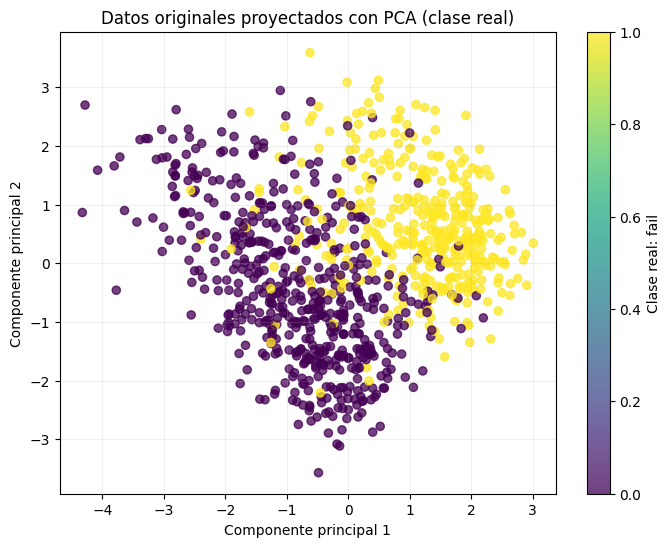

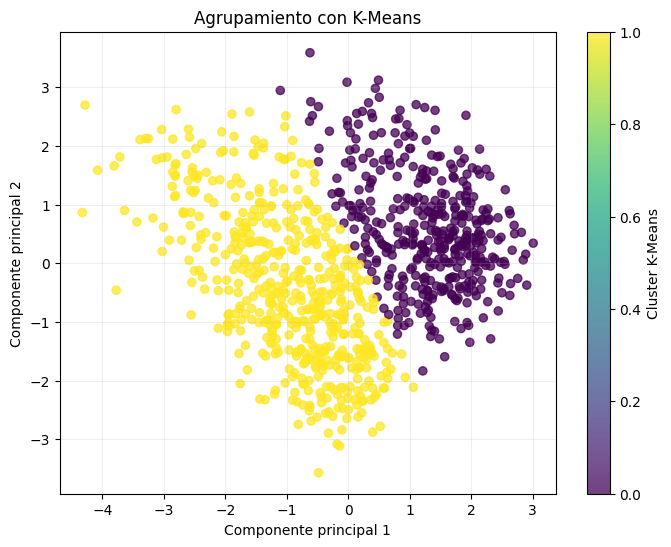

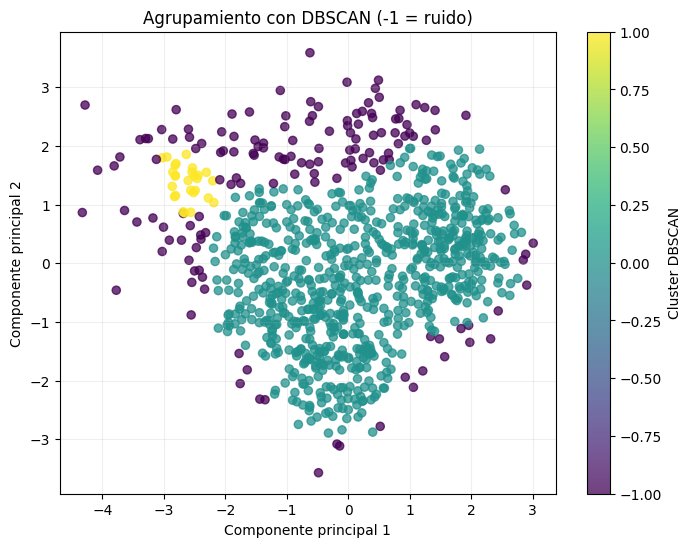

In [40]:
# Gráfica 1: datos originales, coloreados según la clase real fail.
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y_real,
    cmap='viridis',
    s=35,
    alpha=0.75
)
plt.title('Datos originales proyectados con PCA (clase real)')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.colorbar(label='Clase real: fail')
plt.grid(alpha=0.2)
plt.show()

# Gráfica 2: agrupamiento realizado por K-Means.
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_kmeans,
    cmap='viridis',
    s=35,
    alpha=0.75
)
plt.title('Agrupamiento con K-Means')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.colorbar(label='Cluster K-Means')
plt.grid(alpha=0.2)
plt.show()

# Gráfica 3: agrupamiento realizado por DBSCAN.
plt.figure(figsize=(8, 6))
plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters_dbscan,
    cmap='viridis',
    s=35,
    alpha=0.75
)
plt.title('Agrupamiento con DBSCAN (-1 = ruido)')
plt.xlabel('Componente principal 1')
plt.ylabel('Componente principal 2')
plt.colorbar(label='Cluster DBSCAN')
plt.grid(alpha=0.2)
plt.show()